# Flight Delay Prediction Using Machine Learning

**Goal:** predict whether a US domestic flight will arrive **15 or more minutes late**
(`ArrDel15 = 1`) using only information that is known **before departure**.

**Dataset:** Kaggle *Flight Delay Dataset 2018–2022* (`Combined_Flights_2022.parquet`,
which covers January–July 2022).

**Models compared:** Logistic Regression, Decision Tree, Random Forest, Support Vector
Machine (RBF kernel) and Naive Bayes.

**Evaluation:** accuracy, precision, recall, F1 (delayed class), **macro F1** (primary),
ROC-AUC, PR-AUC and confusion matrices, with decision thresholds tuned on
out-of-fold training predictions so the test set stays untouched.

| Phase | Contents |
|---|---|
| 1 | Dataset inspection |
| 2 | Cleaning, feature engineering, sampling, exploratory analysis |
| 3 | Model training with 5-fold cross-validation |
| 4 | Threshold tuning and test-set evaluation |
| 5 | Conclusions and limitations |

## 0. Setup

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 70)
pd.set_option("display.float_format", "{:.3f}".format)

# Folder holding the Kaggle files (Combined_Flights_<YEAR>.parquet)
DATA_DIR = Path(os.environ.get("FLIGHT_DATA_DIR", "~/Desktop/archive")).expanduser()
YEAR = "2022"
SEED = 42
SAMPLE_SIZE = 200_000
SVM_TRAIN_ROWS = 25_000      # kernel SVM scales ~quadratically, so it uses a subset
TARGET = "ArrDel15"

# Chart style
BLUE, ORANGE, INK_2, GRID, SURFACE = "#2a78d6", "#eb6834", "#52514e", "#e4e3df", "#fcfcfb"
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Decision Tree": "#eb6834",
                "Random Forest": "#1baf7a", "SVM (RBF)": "#eda100", "Naive Bayes": "#e87ba4"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "figure.dpi": 110,
})
PCT = PercentFormatter(1.0, decimals=0)
print("Data folder:", DATA_DIR)

Data folder: ~/Desktop/archive


## Phase 1 — Dataset inspection

Load the full 2022 file and check its size, columns, missing values, duplicates and the
target-class distribution before committing to it.

In [2]:
raw = pd.read_parquet(DATA_DIR / f"Combined_Flights_{YEAR}.parquet")
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Memory: {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Dates: {raw['FlightDate'].min():%Y-%m-%d} to {raw['FlightDate'].max():%Y-%m-%d}")
raw.head()

Rows: 4,078,318   Columns: 61
Memory: 2.41 GB
Dates: 2022-01-01 to 2022-07-31


,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,ArrTime,ArrDelayMinutes,AirTime,CRSElapsedTime,ActualElapsedTime,Distance,Year,Quarter,Month,DayofMonth,DayOfWeek,Marketing_Airline_Network,Operated_or_Branded_Code_Share_Partners,DOT_ID_Marketing_Airline,IATA_Code_Marketing_Airline,Flight_Number_Marketing_Airline,Operating_Airline,DOT_ID_Operating_Airline,IATA_Code_Operating_Airline,Tail_Number,Flight_Number_Operating_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,DestCityName,DestState,DestStateFips,DestStateName,DestWac,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
0,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",GJT,DEN,False,False,1133,1123.000,0.000,-10.000,1228.000,0.000,40.000,72.000,65.000,212.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4301,C5,20445,C5,N21144,4301,11921,1192102,31921,"Grand Junction, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,-1.000,1100-1159,17.000,1140.000,1220.000,8.000,1245,-17.000,0.000,-2.000,1200-1259,1,0
1,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",HRL,IAH,False,False,732,728.000,0.000,-4.000,848.000,0.000,55.000,77.000,80.000,295.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4299,C5,20445,C5,N16170,4299,12206,1220605,32206,"Harlingen/San Benito, TX",TX,48,Texas,74,12266,1226603,31453,"Houston, TX",TX,48,Texas,74,0.000,-1.000,0700-0759,16.000,744.000,839.000,9.000,849,-1.000,0.000,-1.000,0800-0859,2,0
2,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1529,1514.000,0.000,-15.000,1636.000,0.000,47.000,70.000,82.000,251.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4298,C5,20445,C5,N21144,4298,11413,1141307,30285,"Durango, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,-1.000,1500-1559,21.000,1535.000,1622.000,14.000,1639,-3.000,0.000,-1.000,1600-1659,2,0
3,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",IAH,GPT,False,False,1435,1430.000,0.000,-5.000,1547.000,0.000,57.000,90.000,77.000,376.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4296,C5,20445,C5,N11184,4296,12266,1226603,31453,"Houston, TX",TX,48,Texas,74,11973,1197302,31973,"Gulfport/Biloxi, MS",MS,28,Mississippi,53,0.000,-1.000,1400-1459,16.000,1446.000,1543.000,4.000,1605,-18.000,0.000,-2.000,1600-1659,2,0
4,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1135,1135.000,0.000,0.000,1251.000,6.000,49.000,70.000,76.000,251.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4295,C5,20445,C5,N17146,4295,11413,1141307,30285,"Durango, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,0.000,1100-1159,19.000,1154.000,1243.000,8.000,1245,6.000,0.000,0.000,1200-1259,2,0


In [3]:
raw.dtypes.to_frame("dtype").T

,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,ArrTime,ArrDelayMinutes,AirTime,CRSElapsedTime,ActualElapsedTime,Distance,Year,Quarter,Month,DayofMonth,DayOfWeek,Marketing_Airline_Network,Operated_or_Branded_Code_Share_Partners,DOT_ID_Marketing_Airline,IATA_Code_Marketing_Airline,Flight_Number_Marketing_Airline,Operating_Airline,DOT_ID_Operating_Airline,IATA_Code_Operating_Airline,Tail_Number,Flight_Number_Operating_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,DestCityName,DestState,DestStateFips,DestStateName,DestWac,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
dtype,datetime64[us],str,str,str,bool,bool,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,str,str,int64,str,int64,str,int64,str,str,int64,int64,int64,int64,str,str,int64,str,int64,int64,int64,int64,str,str,int64,str,int64,float64,float64,str,float64,float64,float64,float64,int64,float64,float64,float64,str,int64,int64


In [4]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "share": missing / len(raw)})

,missing,share
ArrivalDelayGroups,133402,0.033
ArrDel15,133402,0.033
ArrDelayMinutes,133402,0.033
AirTime,133402,0.033
ActualElapsedTime,133402,0.033
ArrDelay,133402,0.033
TaxiIn,124242,0.030
WheelsOn,124242,0.030
ArrTime,124239,0.030
WheelsOff,122666,0.030


In [5]:
print(f"Duplicate rows: {raw.duplicated().sum():,}")
print(f"Cancelled: {raw['Cancelled'].sum():,}   Diverted: {raw['Diverted'].sum():,}")
print("\nTarget distribution (NaN = cancelled/diverted, no arrival):")
print(raw[TARGET].value_counts(dropna=False, normalize=True).rename("share"))

Duplicate rows: 0
Cancelled: 123,192   Diverted: 10,210

Target distribution (NaN = cancelled/diverted, no arrival):
ArrDel15
0.000   0.758
1.000   0.209
NaN     0.033
Name: share, dtype: float64


**Findings**

- ~4.08 million flights, 61 columns, no duplicate rows.
- Missing values (~3%) come almost entirely from cancelled and diverted flights, which
  have no arrival — so no label. Dropping them removes nearly all gaps.
- Among completed flights about **21.7% are delayed**: an imbalance of roughly 3.6 : 1.
  Accuracy alone would be misleading (always predicting "on time" scores ~78%), so we
  focus on **macro F1** and the **delayed-class F1**.
- Many columns are only known **after** take-off (`DepDelay`, `TaxiOut`, `WheelsOff`,
  `AirTime`, `ArrTime`, …). Using them would leak the answer, so they are excluded.

## Phase 2 — Cleaning, feature engineering and exploration

### 2.1 Cleaning

In [6]:
LEAKAGE_COLUMNS = [
    "DepTime", "DepDelay", "DepDelayMinutes", "DepDel15", "DepartureDelayGroups",
    "TaxiOut", "WheelsOff", "WheelsOn", "TaxiIn", "ArrTime", "ArrDelay",
    "ArrDelayMinutes", "ArrivalDelayGroups", "AirTime", "ActualElapsedTime",
    "DivAirportLandings",
]
KEEP = ["FlightDate", "Airline", "Origin", "Dest", "Cancelled", "Diverted",
        "CRSDepTime", "CRSArrTime", "CRSElapsedTime", "Distance", "DistanceGroup",
        "Quarter", "Month", "DayofMonth", "DayOfWeek", "Tail_Number", TARGET]
assert not set(KEEP) & set(LEAKAGE_COLUMNS)

df = raw[KEEP]
df = df[~df["Cancelled"] & ~df["Diverted"]].drop(columns=["Cancelled", "Diverted"])
df = df.dropna(subset=[TARGET, "CRSElapsedTime"]).drop_duplicates()
del raw
print(f"Completed flights after cleaning: {len(df):,}")
print(f"Delayed rate: {df[TARGET].mean():.2%}")

Completed flights after cleaning: 3,944,915
Delayed rate: 21.65%


### 2.2 Feature engineering

All features can be computed from the **published schedule**, so they are available
before departure. Airport traffic and the aircraft's leg of the day are computed on the
full year *before* sampling so they reflect real schedule volumes.

In [7]:
df["dep_hour"] = (df["CRSDepTime"] // 100).clip(0, 23)
df["arr_hour"] = (df["CRSArrTime"] // 100).clip(0, 23)
df["is_weekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)
df["overnight"] = (df["CRSArrTime"] < df["CRSDepTime"]).astype(int)

# Congestion: scheduled flights at each airport that day / hour
df["origin_daily_flights"] = df.groupby(["Origin", "FlightDate"])["Origin"].transform("size")
df["dest_daily_flights"] = df.groupby(["Dest", "FlightDate"])["Dest"].transform("size")
df["origin_hourly_flights"] = df.groupby(["Origin", "FlightDate", "dep_hour"])["Origin"].transform("size")

# Which flight of the day this aircraft is flying (delays carry over between legs)
leg = df.groupby(["Tail_Number", "FlightDate"])["CRSDepTime"].rank(method="first")
df["aircraft_leg_of_day"] = leg.fillna(1).astype(int)

# Days to the nearest US federal holiday (capped at 30)
holidays = USFederalHolidayCalendar().holidays(f"{int(YEAR) - 1}-12-01", f"{int(YEAR) + 1}-01-31")
dates = pd.Series(df["FlightDate"].unique())
gap = dates.map(lambda d: np.abs((holidays - d).days).min())
df["days_to_holiday"] = df["FlightDate"].map(dict(zip(dates, gap))).clip(upper=30)

df[TARGET] = df[TARGET].astype(int)
df.drop(columns=["FlightDate", "Tail_Number", "CRSDepTime", "CRSArrTime"]).head()

,Airline,Origin,Dest,CRSElapsedTime,Distance,DistanceGroup,Quarter,Month,DayofMonth,DayOfWeek,ArrDel15,dep_hour,arr_hour,is_weekend,overnight,origin_daily_flights,dest_daily_flights,origin_hourly_flights,aircraft_leg_of_day,days_to_holiday
0,"Commutair Aka Champlain Enterprises, Inc.",GJT,DEN,72.000,212.000,1,2,4,4,1,0,11,12,0,0,9,726,2,3,30
1,"Commutair Aka Champlain Enterprises, Inc.",HRL,IAH,77.000,295.000,2,2,4,4,1,0,7,8,0,0,12,382,1,1,30
2,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,70.000,251.000,2,2,4,4,1,0,15,16,0,0,9,726,1,5,30
3,"Commutair Aka Champlain Enterprises, Inc.",IAH,GPT,90.000,376.000,2,2,4,4,1,0,14,16,0,0,385,10,49,4,30
4,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,70.000,251.000,2,2,4,4,1,0,11,12,0,0,9,726,1,2,30


### 2.3 Stratified sample

3.9 million rows is more than the SVM can handle, so we draw a **200,000-flight
stratified sample** that keeps the 21.65% delay rate exactly. All models use it, so the
comparison is fair.

In [8]:
CATEGORICAL = ["Airline", "Origin", "Dest"]
NUMERIC = ["CRSElapsedTime", "Distance", "Month", "DayofMonth", "DayOfWeek",
           "dep_hour", "arr_hour", "is_weekend", "overnight",
           "origin_daily_flights", "dest_daily_flights", "origin_hourly_flights",
           "aircraft_leg_of_day", "days_to_holiday"]
FEATURES = CATEGORICAL + NUMERIC

frac = SAMPLE_SIZE / len(df)
sample = (df[FEATURES + ["DistanceGroup", "Quarter", TARGET]]
          .groupby(TARGET, group_keys=False).sample(frac=frac, random_state=SEED)
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
full_rate = df[TARGET].mean()
del df
print(f"Sample: {len(sample):,} rows, delayed rate {sample[TARGET].mean():.2%} (full data {full_rate:.2%})")
print(f"Missing values in sample: {sample.isna().sum().sum()}")

Sample: 200,000 rows, delayed rate 21.65% (full data 21.65%)
Missing values in sample: 0


### 2.4 Exploratory data analysis

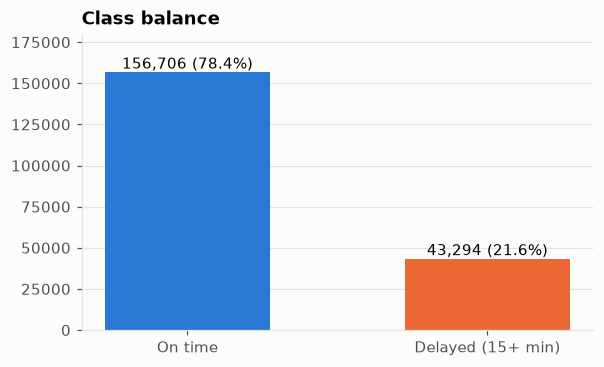

In [9]:
OVERALL = sample[TARGET].mean()

def rate_bar(ax, series, labels=None, horizontal=False, title="", xlabel=""):
    labels = labels if labels is not None else series.index.astype(str)
    if horizontal:
        ax.barh(labels, series.values, color=BLUE, height=0.6)
        ax.axvline(OVERALL, color=INK_2, ls="--", lw=1, label=f"Overall ({OVERALL:.1%})")
        ax.xaxis.set_major_formatter(PCT); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Share of flights delayed")
    else:
        ax.bar(labels, series.values, color=BLUE, width=0.65)
        ax.axhline(OVERALL, color=INK_2, ls="--", lw=1, label=f"Overall ({OVERALL:.1%})")
        ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
        ax.set_ylabel("Share of flights delayed"); ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="lower right" if horizontal else "upper left")

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = sample[TARGET].value_counts().sort_index()
ax.bar(["On time", "Delayed (15+ min)"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,} ({n / len(sample):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15); ax.set_title("Class balance"); ax.grid(axis="x", visible=False)
plt.show()

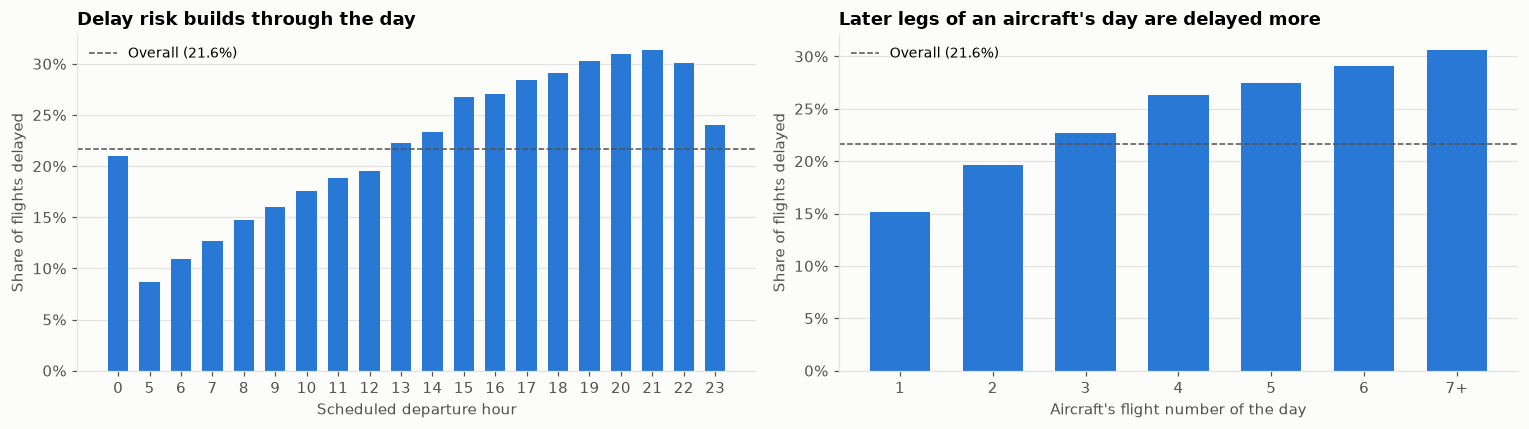

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_hour = sample.groupby("dep_hour")[TARGET].agg(["mean", "size"])
rate_bar(axes[0], by_hour.loc[by_hour["size"] >= 200, "mean"],
         title="Delay risk builds through the day", xlabel="Scheduled departure hour")
leg = sample.groupby(sample["aircraft_leg_of_day"].clip(upper=7))[TARGET].mean()
rate_bar(axes[1], leg, labels=[str(i) if i < 7 else "7+" for i in leg.index],
         title="Later legs of an aircraft's day are delayed more",
         xlabel="Aircraft's flight number of the day")
plt.tight_layout(); plt.show()

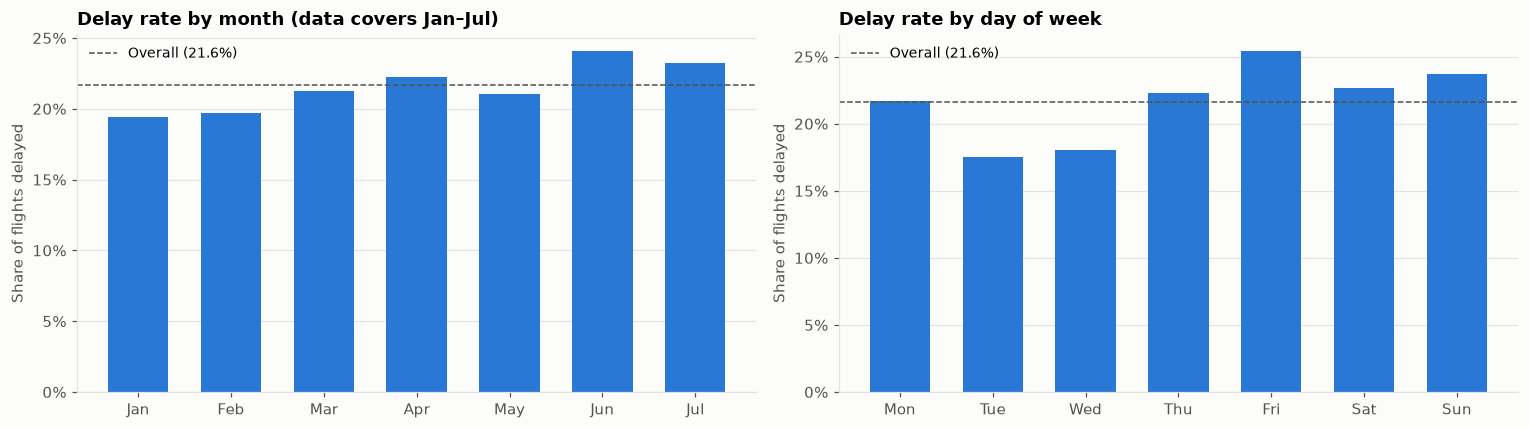

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = sample.groupby("Month")[TARGET].mean()
rate_bar(axes[0], by_month, labels=[months[m - 1] for m in by_month.index],
         title="Delay rate by month (data covers Jan–Jul)")
by_dow = sample.groupby("DayOfWeek")[TARGET].mean()
rate_bar(axes[1], by_dow, labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
         title="Delay rate by day of week")
plt.tight_layout(); plt.show()

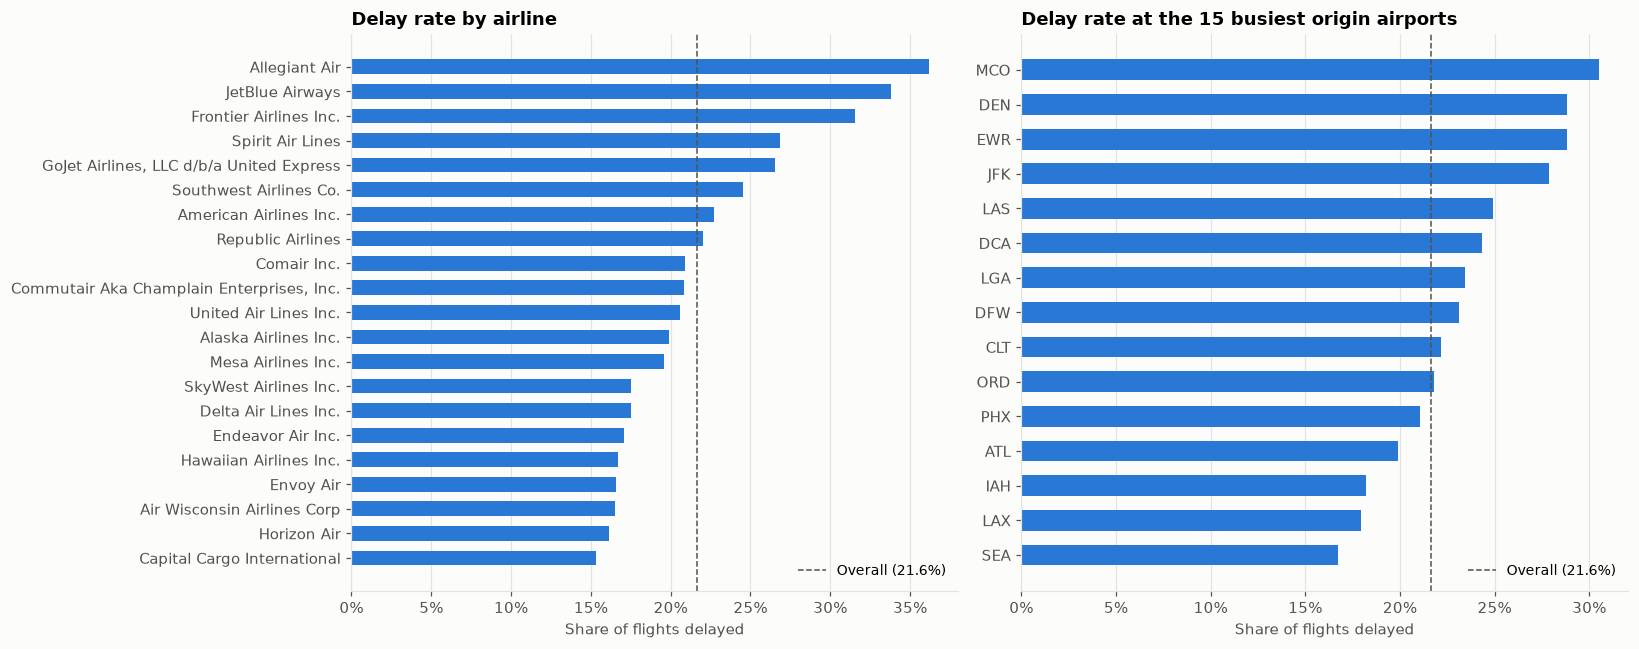

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
by_airline = sample.groupby("Airline")[TARGET].agg(["mean", "size"])
rate_bar(axes[0], by_airline[by_airline["size"] >= 500]["mean"].sort_values(), horizontal=True,
         title="Delay rate by airline")
top = sample["Origin"].value_counts().head(15).index
rate_bar(axes[1], sample[sample["Origin"].isin(top)].groupby("Origin")[TARGET].mean().sort_values(),
         horizontal=True, title="Delay rate at the 15 busiest origin airports")
plt.tight_layout(); plt.show()

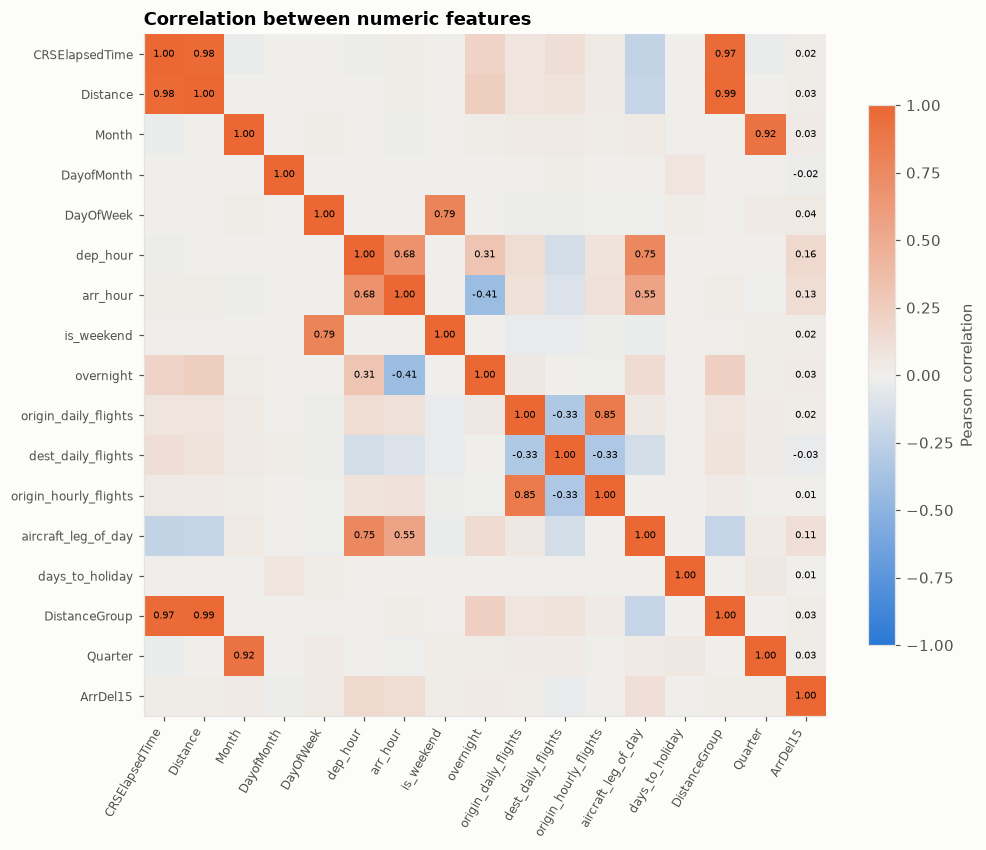

,corr with ArrDel15
dep_hour,0.161
arr_hour,0.129
aircraft_leg_of_day,0.114
DayOfWeek,0.041
Month,0.034
overnight,0.034
dest_daily_flights,-0.032
Quarter,0.029
DistanceGroup,0.028
Distance,0.027


In [13]:
corr = sample.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap=LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE]),
               vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iat[i, j]) >= 0.3 or corr.columns[j] == TARGET:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson correlation")
ax.set_title("Correlation between numeric features"); plt.show()

corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).to_frame("corr with ArrDel15")

**EDA findings**

- **Time of day** is the strongest single signal: ~9% of 5 am departures are late vs ~31% around 9 pm.
- **Aircraft leg of the day:** 15% on the first flight, rising to ~31% by the seventh — delays propagate.
- **Airlines** range from ~15% to ~36%; **airports** such as MCO, DEN and EWR are worst.
- `Distance`, `DistanceGroup` and `CRSElapsedTime` correlate at 0.97–0.99, and `Quarter`
  with `Month` at 0.92, so `DistanceGroup` and `Quarter` are **not** used as model features.
- Each single feature is weak (|r| ≤ 0.16), so realistic macro F1 scores are around 0.55–0.65.

## Phase 3 — Model training

- **80/20 stratified split.** The test set is not used until Phase 4.
- Each model is a `Pipeline`, so encoders are fitted only on training folds (no leakage):
  - Logistic Regression and SVM: one-hot encoding of airline/airports + standardised numerics.
  - Decision Tree, Random Forest and Naive Bayes: cross-fitted **target encoding** of
    airline/airports (one number per category) + numerics.
- `class_weight="balanced"` compensates for the 3.6 : 1 imbalance.
- **5-fold stratified cross-validation** on the training set. The out-of-fold probabilities
  are kept for threshold tuning in Phase 4.

In [14]:
X, y = sample[FEATURES], sample[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,}  Test: {len(X_test):,}  "
      f"(delayed {y_train.mean():.2%} / {y_test.mean():.2%})")

Train: 160,000  Test: 40,000  (delayed 21.65% / 21.65%)


In [15]:
def one_hot_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CATEGORICAL),
        ("num", StandardScaler(), NUMERIC)])

def target_enc_prep(scale=False):
    return ColumnTransformer([
        ("cat", TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=SEED)), CATEGORICAL),
        ("num", StandardScaler() if scale else "passthrough", NUMERIC)])

models = {
    "Logistic Regression": Pipeline([
        ("prep", one_hot_prep()),
        ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))]),
    "Decision Tree": Pipeline([
        ("prep", target_enc_prep()),
        ("clf", DecisionTreeClassifier(max_depth=12, min_samples_leaf=50,
                                       class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([
        ("prep", target_enc_prep()),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=18, min_samples_leaf=5,
                                       max_features="sqrt", class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=SEED))]),
    # Platt (sigmoid) calibration gives the SVM probabilities for ROC-AUC and thresholds
    "SVM (RBF)": Pipeline([
        ("prep", one_hot_prep()),
        ("clf", CalibratedClassifierCV(
            SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED),
            method="sigmoid", ensemble=False))]),
    "Naive Bayes": Pipeline([
        ("prep", target_enc_prep(scale=True)),
        ("clf", GaussianNB())]),
}

In [16]:
SCORING = {"accuracy": "accuracy", "precision_delayed": "precision", "recall_delayed": "recall",
           "f1_delayed": "f1", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows, oof = [], {}

for name, pipe in models.items():
    Xt, yt = X_train, y_train
    if name.startswith("SVM"):
        Xt, _, yt, _ = train_test_split(X_train, y_train, train_size=SVM_TRAIN_ROWS,
                                        stratify=y_train, random_state=SEED)
    start = time.time()
    scores = cross_validate(pipe, Xt, yt, cv=cv, scoring=SCORING,
                            return_estimator=True, return_indices=True)
    # Out-of-fold probability for each training row, from the fold model that did not see it
    proba = np.empty(len(Xt))
    for est, idx in zip(scores["estimator"], scores["indices"]["test"]):
        proba[idx] = est.predict_proba(Xt.iloc[idx])[:, 1]
    oof[name] = (yt.to_numpy(), proba)

    pipe.fit(Xt, yt)   # final model on all its training rows
    row = {"Model": name, "Train rows": len(Xt)}
    for m in SCORING:
        row[m] = scores[f"test_{m}"].mean()
    row["macro F1 std"] = scores["test_f1_macro"].std()
    row["seconds"] = time.time() - start
    cv_rows.append(row)
    print(f"{name:<20} CV macro F1 {row['f1_macro']:.3f} ± {row['macro F1 std']:.3f}  ({row['seconds']:.0f}s)")

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results

Logistic Regression  CV macro F1 0.560 ± 0.003  (8s)


Decision Tree        CV macro F1 0.566 ± 0.004  (5s)


Random Forest        CV macro F1 0.618 ± 0.002  (73s)


SVM (RBF)            CV macro F1 0.454 ± 0.002  (517s)


Naive Bayes          CV macro F1 0.550 ± 0.004  (2s)


,Train rows,accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,macro F1 std,seconds
Model,,,,,,,,,
Logistic Regression,160000,0.613,0.305,0.614,0.407,0.560,0.653,0.003,7.545
Decision Tree,160000,0.628,0.308,0.575,0.401,0.566,0.646,0.004,5.322
Random Forest,160000,0.763,0.439,0.341,0.384,0.618,0.695,0.002,72.807
SVM (RBF),25000,0.784,0.540,0.015,0.029,0.454,0.665,0.002,516.517
Naive Bayes,160000,0.752,0.360,0.190,0.249,0.550,0.635,0.004,2.095


These cross-validation scores use the default 0.5 threshold. The calibrated SVM and
Naive Bayes rarely output probabilities above 0.5, so they look weak here — Phase 4 fixes
this by tuning each model's threshold.

## Phase 4 — Threshold tuning and test-set evaluation

### 4.1 Threshold tuning (training data only)

For each model, choose the threshold that maximises **macro F1 on the out-of-fold
training predictions**. The test set is not used to choose anything.

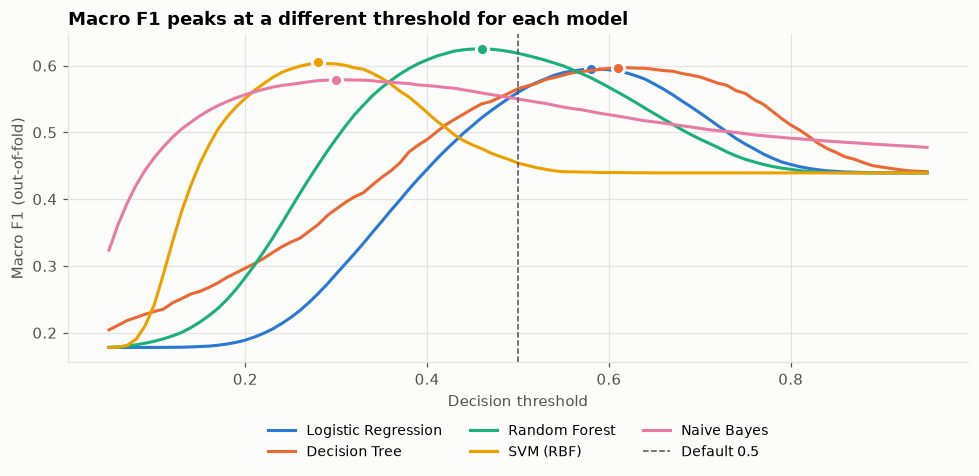

,tuned threshold
Logistic Regression,0.580
Decision Tree,0.610
Random Forest,0.460
SVM (RBF),0.280
Naive Bayes,0.300


In [17]:
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)
best_threshold, curves = {}, {}
for name, (yt, proba) in oof.items():
    curves[name] = np.array([f1_score(yt, proba >= t, average="macro") for t in THRESHOLDS])
    best_threshold[name] = float(THRESHOLDS[curves[name].argmax()])

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, curve in curves.items():
    ax.plot(THRESHOLDS, curve, color=MODEL_COLORS[name], lw=2, label=name)
    ax.plot(best_threshold[name], curve.max(), "o", ms=8, color=MODEL_COLORS[name], mec=SURFACE, mew=2)
ax.axvline(0.5, color=INK_2, ls="--", lw=1, label="Default 0.5")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Macro F1 (out-of-fold)")
ax.set_title("Macro F1 peaks at a different threshold for each model")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()
pd.Series(best_threshold, name="tuned threshold").to_frame()

### 4.2 Test-set results

In [18]:
def evaluate(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return {"threshold": t,
            "accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "precision_delayed": precision_score(y_true, pred),
            "recall_delayed": recall_score(y_true, pred),
            "f1_delayed": f1_score(y_true, pred),
            "f1_macro": f1_score(y_true, pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

def bootstrap_ci(y_true, pred, n=500):
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(y_true), size=(n, len(y_true)))
    return np.percentile([f1_score(y_true[i], pred[i], average="macro") for i in idx], [2.5, 97.5])

y_true = y_test.to_numpy()
test_proba = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in models.items()}
default_res = pd.DataFrame({n: evaluate(y_true, p, 0.5) for n, p in test_proba.items()}).T
tuned_res = pd.DataFrame({n: evaluate(y_true, p, best_threshold[n]) for n, p in test_proba.items()}).T
for name, p in test_proba.items():
    lo, hi = bootstrap_ci(y_true, (p >= best_threshold[name]).astype(int))
    tuned_res.loc[name, "macro F1 95% CI"] = f"{lo:.3f}–{hi:.3f}"
order = tuned_res.sort_values("f1_macro", ascending=False).index

print("Default threshold 0.5:")
display(default_res.loc[order])
print("Tuned thresholds:")
tuned_res.loc[order]

Default threshold 0.5:


,threshold,accuracy,balanced_accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,pr_auc
Random Forest,0.500,0.765,0.618,0.446,0.360,0.398,0.626,0.697,0.404
SVM (RBF),0.500,0.785,0.507,0.570,0.019,0.036,0.458,0.670,0.360
Decision Tree,0.500,0.626,0.613,0.309,0.591,0.406,0.566,0.652,0.350
Logistic Regression,0.500,0.619,0.617,0.309,0.614,0.411,0.564,0.659,0.356
Naive Bayes,0.500,0.756,0.553,0.376,0.196,0.258,0.556,0.641,0.317


Tuned thresholds:


,threshold,accuracy,balanced_accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,pr_auc,macro F1 95% CI
Random Forest,0.460,0.743,0.633,0.413,0.438,0.425,0.630,0.697,0.404,0.624–0.635
SVM (RBF),0.280,0.719,0.613,0.371,0.426,0.396,0.607,0.670,0.360,0.601–0.612
Decision Tree,0.610,0.725,0.599,0.368,0.377,0.373,0.598,0.652,0.350,0.593–0.604
Logistic Regression,0.580,0.715,0.601,0.358,0.401,0.378,0.597,0.659,0.356,0.592–0.602
Naive Bayes,0.300,0.695,0.592,0.333,0.410,0.368,0.583,0.641,0.317,0.578–0.589


In [19]:
for name in order:
    pred = (test_proba[name] >= best_threshold[name]).astype(int)
    print(f"=== {name} (threshold {best_threshold[name]:.2f}) ===")
    print(classification_report(y_true, pred, target_names=["On time", "Delayed"], digits=3))

=== Random Forest (threshold 0.46) ===
              precision    recall  f1-score   support

     On time      0.842     0.828     0.835     31341
     Delayed      0.413     0.438     0.425      8659

    accuracy                          0.743     40000
   macro avg      0.627     0.633     0.630     40000
weighted avg      0.749     0.743     0.746     40000

=== SVM (RBF) (threshold 0.28) ===
              precision    recall  f1-score   support

     On time      0.835     0.800     0.817     31341
     Delayed      0.371     0.426     0.396      8659

    accuracy                          0.719     40000
   macro avg      0.603     0.613     0.607     40000
weighted avg      0.734     0.719     0.726     40000

=== Decision Tree (threshold 0.61) ===
              precision    recall  f1-score   support

     On time      0.827     0.821     0.824     31341
     Delayed      0.368     0.377     0.373      8659

    accuracy                          0.725     40000
   macro avg   

### 4.3 Confusion matrices

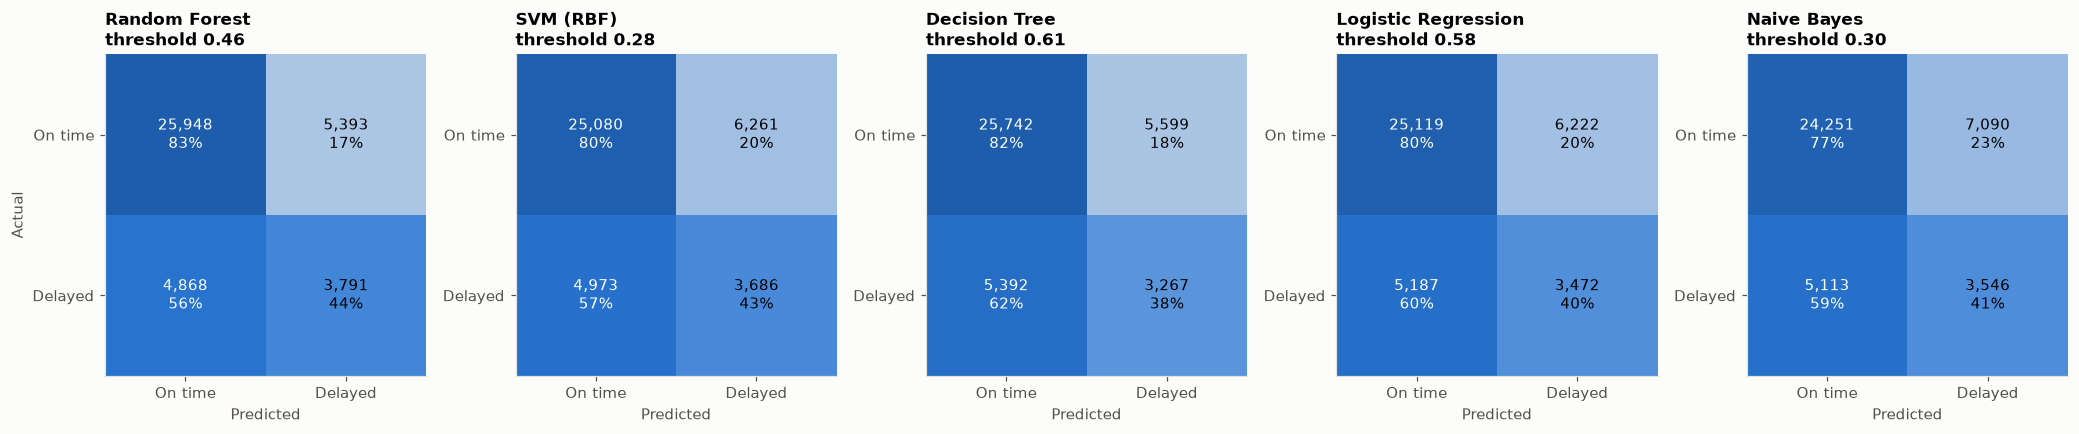

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#2a78d6", "#184f95"])
for ax, name in zip(axes, order):
    cm = confusion_matrix(y_true, test_proba[name] >= best_threshold[name])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center",
                    color="white" if share[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["On time", "Delayed"]); ax.set_yticks([0, 1], ["On time", "Delayed"])
    ax.set_xlabel("Predicted"); ax.grid(False)
    ax.set_title(f"{name}\nthreshold {best_threshold[name]:.2f}", fontsize=11)
axes[0].set_ylabel("Actual")
plt.tight_layout(); plt.show()

### 4.4 ROC and precision–recall curves

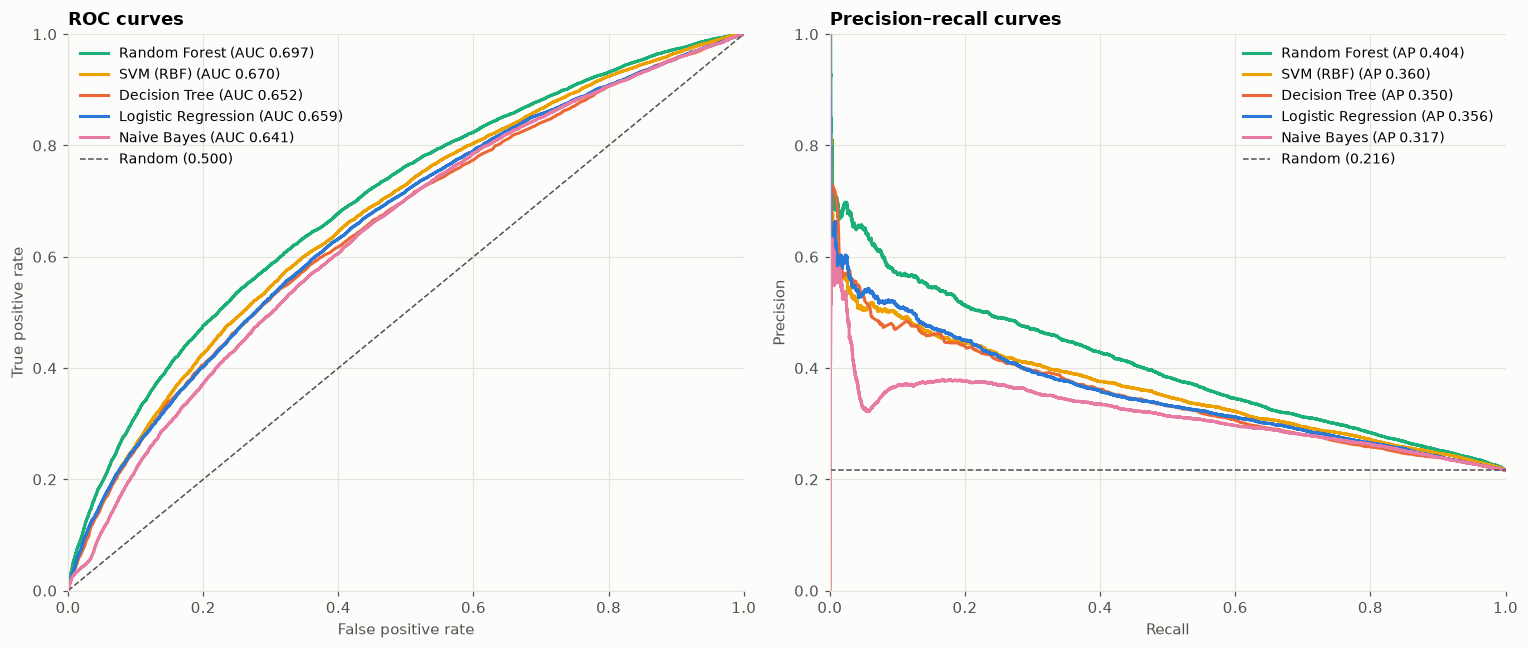

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in order:
    fpr, tpr, _ = roc_curve(y_true, test_proba[name])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2,
                 label=f"{name} (AUC {tuned_res.loc[name, 'roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_true, test_proba[name])
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], lw=2,
                 label=f"{name} (AP {tuned_res.loc[name, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1, label="Random (0.500)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves", xlim=(0, 1), ylim=(0, 1))
axes[1].axhline(y_true.mean(), color=INK_2, ls="--", lw=1, label=f"Random ({y_true.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves", xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### 4.5 Model comparison

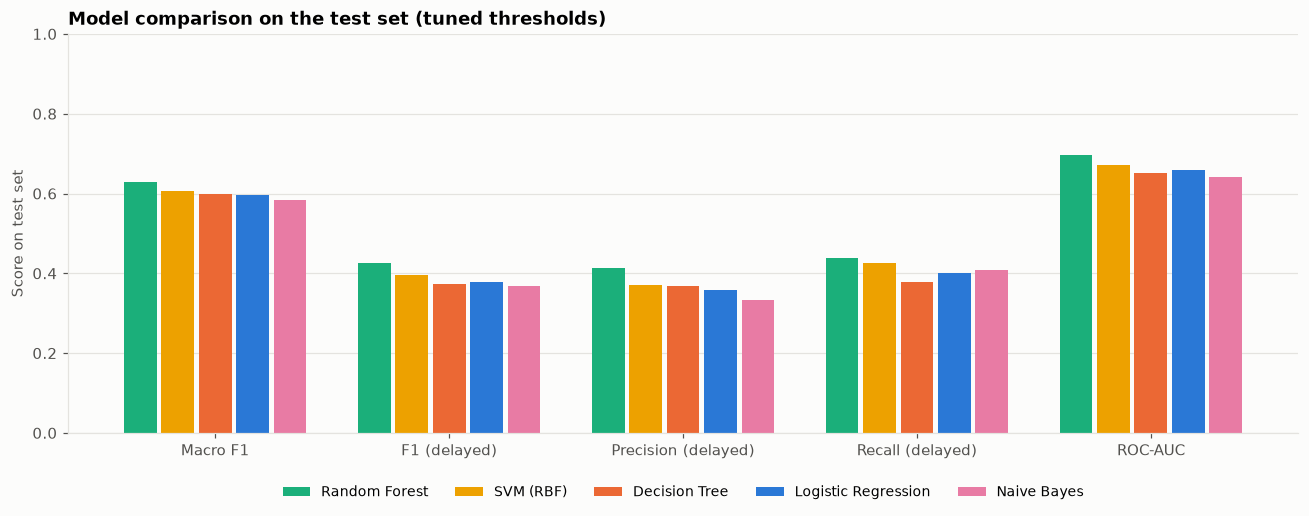

In [22]:
metric_names = {"f1_macro": "Macro F1", "f1_delayed": "F1 (delayed)", "precision_delayed": "Precision (delayed)",
                "recall_delayed": "Recall (delayed)", "roc_auc": "ROC-AUC"}
fig, ax = plt.subplots(figsize=(12, 4.8))
x, width = np.arange(len(metric_names)), 0.16
for i, name in enumerate(order):
    ax.bar(x + (i - 2) * width, tuned_res.loc[name, list(metric_names)].astype(float),
           width=width - 0.02, color=MODEL_COLORS[name], label=name)
ax.set_xticks(x, metric_names.values()); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
ax.set_ylabel("Score on test set"); ax.set_title("Model comparison on the test set (tuned thresholds)")
ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

### 4.6 What drives the best model?

Permutation importance: how much the test ROC-AUC drops when one feature's values are
shuffled (10,000 test flights, 5 repeats).

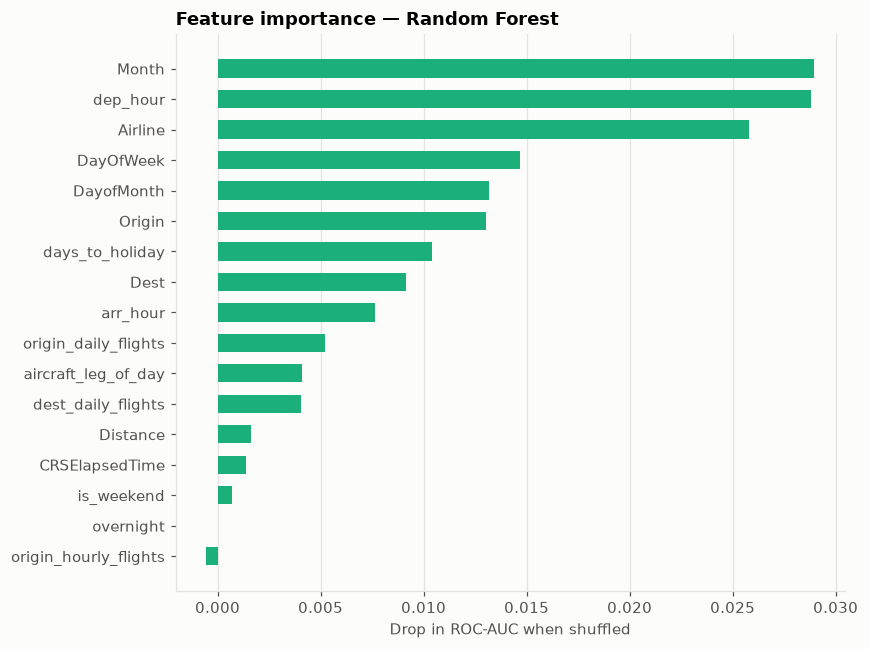

In [23]:
best = order[0]
sub = np.random.default_rng(SEED).choice(len(X_test), size=10_000, replace=False)
imp = permutation_importance(models[best], X_test.iloc[sub], y_true[sub], scoring="roc_auc",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=MODEL_COLORS[best], height=0.6)
ax.set_xlabel("Drop in ROC-AUC when shuffled"); ax.set_title(f"Feature importance — {best}")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Phase 5 — Conclusions

1. **Random Forest is the best model** on macro F1, delayed-class F1, ROC-AUC and PR-AUC,
   and its 95% confidence interval for macro F1 does not overlap any other model's.
2. **Threshold tuning matters.** With the default 0.5 threshold the calibrated SVM almost never
   predicts "delayed"; tuning on out-of-fold training predictions makes it the second-best model.
3. **Naive Bayes is weakest**, because its independence assumption is violated (departure hour,
   arrival hour and aircraft leg are strongly correlated).
4. **Key drivers:** month, scheduled departure hour and airline, then day of week and origin airport.
5. Scores are moderate (ROC-AUC ≈ 0.70) but clearly better than chance (PR-AUC ≈ 0.40 vs 0.22
   for random guessing), which is realistic for genuine *pre-departure* prediction.

### Limitations and future work

- The 2022 file covers only January–July, so seasonal effects are partial.
- The train/test split is random, not time-based; a forward-in-time split would be stricter.
- No weather or air-traffic-control data — the main real causes of delay.
- The SVM is trained on a 25,000-flight subset because kernel SVM scales quadratically.
- Future work: add weather data, use several years with a time-based split, and try gradient boosting.